# Part 1 — Factor Investing

**FE5108 Portfolio Theory and Investments · Fall 2026 class project — practitioner segment**  
Data: Fama-French (US Research Returns), MSCI USA index levels, MSCI Momentum Index methodology (Dec 2013).

---

### Executive summary

| # | Finding |
|---|---|
| 1 | **Factor premia decayed, but unevenly.** In 1927–1992 all three FF3 premia were significant (Mkt–RF *t* = 3.2, SMB *t* = 2.1, HML *t* = 3.3). Since 1993 only the market premium remains significant (*t* = 3.1); SMB (*t* = 0.6) and HML (*t* = 0.8) are no longer distinguishable from zero. |
| 2 | **Momentum is the strongest but most regime-dependent premium.** The value-weighted winners-minus-losers decile spread averaged **+13.6%/yr** (1927–2023), but in the highest trailing-volatility tercile it averaged **−12.3%/yr**, and high volatility hits its left tail hardest (quantile slope **−0.85**, *t* = −5.4 at the 10th percentile). |
| 3 | **Diversification pays.** Among investable MSCI USA indexes (1995–2023), Momentum (Sharpe 0.69) and Min Vol (0.68) beat the market (0.59) and the multi-factor average earned a **higher Sharpe than the market with lower volatility** (0.64 vs 0.59; 14.4% vs 15.4%). |
| 4 | **MSCI smart-beta spreads are recognisable but not identical to academic factors.** Value ↔ HML ρ = **0.73**, Min Vol ↔ BAB ρ = **0.81**, Momentum ↔ UMD ρ = **0.64**; Equal-Weight is the least factor-like tilt. Construction choices (universe, weighting, rebalancing) matter. |
| 5 | **MSCI's momentum recipe explains both.** Score × parent-cap weighting, a 5% issuer cap and semi-annual plus volatility-triggered rebalancing keep the index liquid and close to the parent — at the cost of a diluted, sometimes off-cycle momentum signal. |

*All Fama-French returns are in percent per month (0.23 = 0.23%). MSCI index returns are computed from gross USD index levels. All exhibits are also saved in `exports/part1/`.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from scipy import stats
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess
from pathlib import Path

from qbstyles import mpl_style

from goldman2 import load_ff3, load_msci_returns, load_portfolios

# --- house style -----------------------------------------------------------------
# minor_ticks=False avoids qbstyles' overlay-axes monkey patch (matplotlib>=3.9)
mpl_style(dark=False, minor_ticks=False)
plt.rcParams.update({
    "figure.facecolor": "white",
    "figure.dpi": 110,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "font.size": 10,
    "legend.frameon": False,
    "axes.grid": True,
})

# semantic colours (qbstyles / ColorBrewer Paired palette)
C = {
    "market": "#1F78B4", "value": "#33A02C", "minvol": "#6A3D9A",
    "ew": "#FF7F00", "momentum": "#E31A1C", "multi": "#008B8B",
    "pos": "#33A02C", "neg": "#E31A1C", "neutral": "#777777",
}

REPO = Path.cwd()
while not (REPO / "pyproject.toml").exists():
    REPO = REPO.parent
EXPORTS = REPO / "exports" / "part1"
EXPORTS.mkdir(parents=True, exist_ok=True)


def save_exhibit(fig, name):
    """Save the current exhibit for the write-up and display it inline."""
    fig.savefig(EXPORTS / f"{name}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()


def pct(x, digits=1):
    return f"{x:+.{digits}f}"


# --- data ------------------------------------------------------------------------
ff3 = load_ff3()                                    # % per month, PeriodIndex
beta_vw = load_portfolios("beta")["value_monthly"]  # beta quintiles + deciles
mom_vw = load_portfolios("pmom")["value_monthly"]   # prior-return deciles
msci = load_msci_returns()                          # MSCI USA family, % per month

# The two academic long-short spreads used again in 1D and 1E:
bab = beta_vw["Lo 10"] - beta_vw["Hi 10"]           # low-beta minus high-beta
umd = mom_vw["Hi PRIOR"] - mom_vw["Lo PRIOR"]       # winners minus losers

print(f"FF3: {ff3.index[0]} to {ff3.index[-1]} ({len(ff3)} months)")
print(f"Beta spread: {bab.index[0]} to {bab.index[-1]} | Momentum spread: {umd.index[0]} to {umd.index[-1]}")
print(f"MSCI returns: {msci.index[0]} to {msci.index[-1]} ({len(msci)} months)")

FF3: 1926-07 to 2023-07 (1165 months)
Beta spread: 1963-07 to 2023-07 | Momentum spread: 1927-01 to 2023-07
MSCI returns: 1995-01 to 2023-07 (343 months)


## 1A · Factor premiums and factor decay

> **Question.** Estimate the *t*-statistics of the average market, value and small-size premia for 1927–1992 and for 1993–July 2023. Comment on whether they all remain high-conviction ideas. Then build the value-weighted low-minus-high beta and winners-minus-losers momentum spreads for later use.

The FF data begin in July 1926; we drop the partial first six months so that the "pre-publication" window is exactly January 1927 – December 1992, as requested.

**Arithmetic vs geometric mean.** The premia are *return spreads* (zero-investment long–short combinations), not investable portfolio returns that compound from a positive capital base. A geometric average of a series that can be negative or cross zero is undefined or meaningless, so the significance test of the average premium uses the **arithmetic** mean, and the *t*-statistic ignores autocorrelation as instructed:

$$ t = \frac{\bar r}{s / \sqrt{N}}, \qquad \bar r_{\text{ann}} = 12\,\bar r. $$

In [2]:
FACTORS = {"Mkt-RF": "Market (Mkt–RF)", "SMB": "Size (SMB)", "HML": "Value (HML)"}
periods = {
    "1927–1992": ff3.loc["1927-01":"1992-12"],
    "1993–2023.07": ff3.loc["1993-01":],
}

rows = []
for period, frame in periods.items():
    for factor, label in FACTORS.items():
        x = frame[factor]
        t, p = stats.ttest_1samp(x, 0.0)
        rows.append({
            "Factor": label,
            "Period": period,
            "N": len(x),
            "Mean %/mo": x.mean(),
            "Ann. mean %/yr": x.mean() * 12,
            "Ann. vol %": x.std(ddof=1) * np.sqrt(12),
            "t-stat": t,
            "p-value": p,
        })

premium_table = pd.DataFrame(rows).set_index(["Factor", "Period"])
(
    premium_table.style
    .format({"N": "{:.0f}", "Mean %/mo": "{:.3f}", "Ann. mean %/yr": "{:+.2f}",
             "Ann. vol %": "{:.1f}", "t-stat": "{:.2f}", "p-value": "{:.3f}"})
    .set_caption("Table 1A.1 — FF3 average premia and t-statistics by period (monthly %, arithmetic means).")
    .background_gradient(subset=["t-stat"], cmap="RdYlGn")
)

,,N,Mean %/mo,Ann. mean %/yr,Ann. vol %,t-stat,p-value
Factor,Period,,,,,,
Market (Mkt–RF),1927–1992,792,0.655,+7.86,19.8,3.22,0.001
Size (SMB),1927–1992,792,0.240,+2.88,11.0,2.13,0.034
Value (HML),1927–1992,792,0.435,+5.22,12.7,3.33,0.001
Market (Mkt–RF),1993–2023.07,367,0.719,+8.62,15.4,3.09,0.002
Size (SMB),1993–2023.07,367,0.099,+1.19,11.0,0.60,0.549
Value (HML),1993–2023.07,367,0.146,+1.75,11.6,0.83,0.407


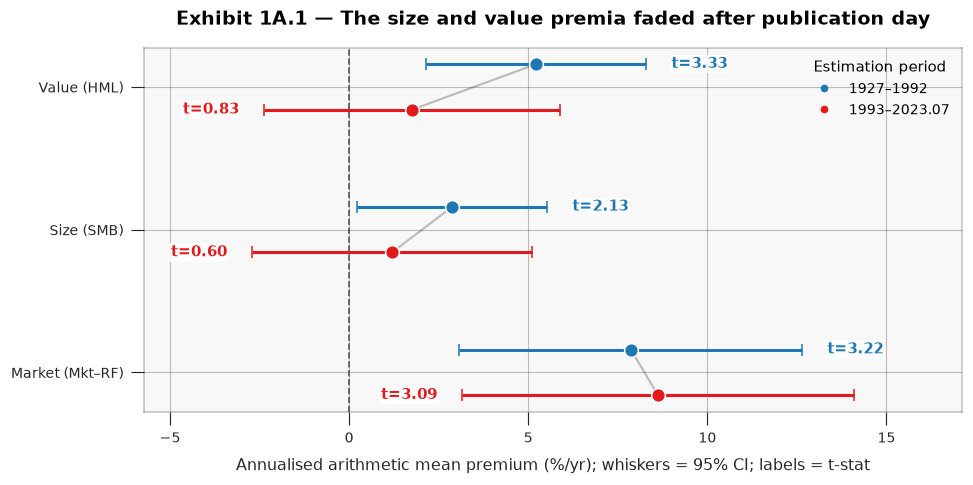

In [3]:
# Exhibit 1A.1 — premium decay: annualised mean with 95% confidence interval
fig, ax = plt.subplots(figsize=(9.6, 4.3))
colours = {"1927–1992": C["market"], "1993–2023.07": C["momentum"]}

for i, (factor, label) in enumerate(FACTORS.items()):
    stats_row = premium_table.loc[(label, slice(None))].reset_index()
    for j, row in stats_row.iterrows():
        m = row["Ann. mean %/yr"]
        se = row["Ann. vol %"] * np.sqrt(12) / np.sqrt(row["N"])   # SE of the annualised mean
        y = i + (0.16 if j == 0 else -0.16)
        c = colours[row["Period"]]
        ci = 1.96 * se
        ax.errorbar(m, y, xerr=ci, fmt="o", color=c, markersize=9,
                    capsize=4, lw=2, markeredgecolor="white", markeredgewidth=1.0, zorder=3)
        lx = m + ci + 0.7 if j == 0 else m - ci - 0.7
        ax.text(lx, y, f"t={row['t-stat']:.2f}", ha="left" if j == 0 else "right", va="center",
                fontsize=9.5, color=c, fontweight="bold", zorder=4,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.2))
    ax.plot(stats_row["Ann. mean %/yr"], [i + 0.16, i - 0.16],
            color="#BBBBBB", lw=1.4, zorder=1)

ax.axvline(0, color="#555555", lw=1.1, ls="--")
ax.set_yticks(range(len(FACTORS)), [FACTORS[f] for f in FACTORS])
ax.set_xlabel("Annualised arithmetic mean premium (%/yr); whiskers = 95% CI; labels = t-stat")
ax.set_title("Exhibit 1A.1 — The size and value premia faded after publication day")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=p) for p, c in colours.items()]
ax.legend(handles=handles, loc="upper right", title="Estimation period")
ax.margins(x=0.18)
save_exhibit(fig, "1a_premium_decay_ci")

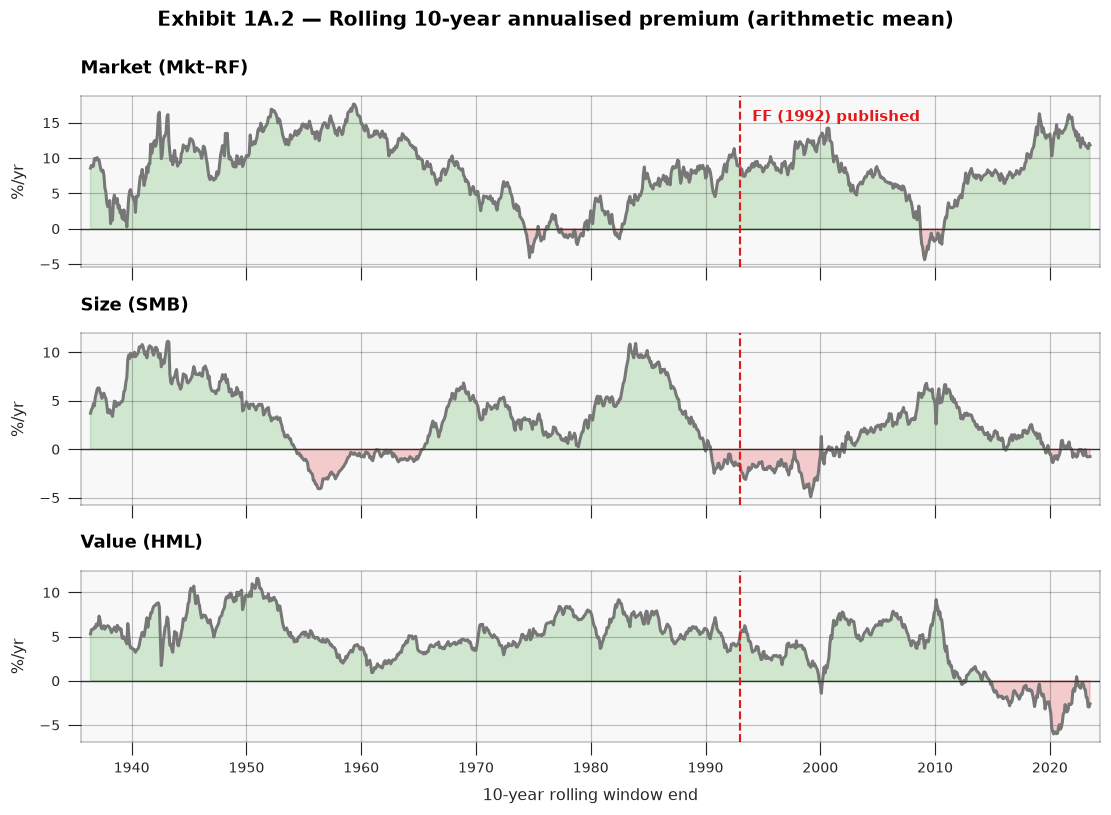

In [4]:
# Exhibit 1A.2 — rolling 10-year annualised premium, small multiples with sign shading
factors = list(FACTORS)
roll = {f: ff3[f].rolling(120).mean() * 12 for f in factors}

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(10.2, 7.4))
for ax, factor in zip(axes, factors):
    s = roll[factor].dropna()
    x = s.index.to_timestamp()
    ax.fill_between(x, s, 0, where=s >= 0, color=C["pos"], alpha=0.20, interpolate=True)
    ax.fill_between(x, s, 0, where=s < 0, color=C["neg"], alpha=0.20, interpolate=True)
    ax.plot(x, s, color=C["neutral"], lw=2.0)
    ax.axhline(0, color="#333333", lw=0.9)
    ax.axvline(pd.Timestamp("1993-01-01"), color=C["momentum"], lw=1.4, ls="--")
    ax.set_ylabel("%/yr")
    ax.set_title(FACTORS[factor], loc="left", fontsize=11.5)
    ax.margins(x=0.01)
axes[0].annotate("FF (1992) published", xy=(pd.Timestamp("1993-01-01"), 0.92),
                 xycoords=("data", "axes fraction"), xytext=(8, 0), textcoords="offset points",
                 color=C["momentum"], fontsize=9.5, fontweight="bold", va="top")
axes[-1].set_xlabel("10-year rolling window end")
fig.suptitle("Exhibit 1A.2 — Rolling 10-year annualised premium (arithmetic mean)",
             fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()
save_exhibit(fig, "1a_rolling_premia")

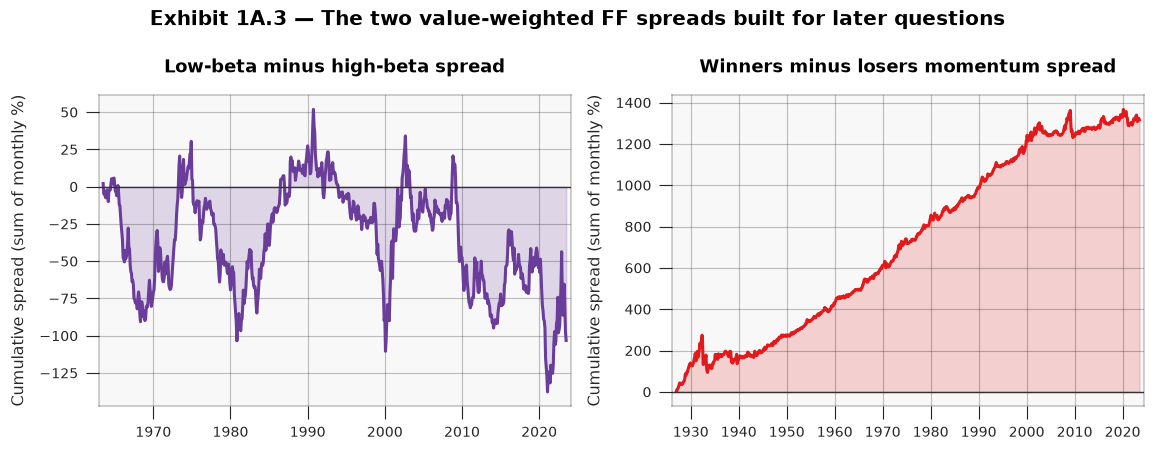

,Ann. mean %/yr,Ann. vol %,t-stat (full history),Sample
Low-beta minus high-beta (Lo 10 − Hi 10),-1.72,23.92,-0.56,1963-07 to 2023-07
Winners minus losers (Hi − Lo PRIOR),+13.63,27.35,4.90,1927-01 to 2023-07


In [5]:
# The two long-short spreads reused in 1D and 1E
spread_table = pd.DataFrame({
    "Low-beta minus high-beta (Lo 10 − Hi 10)": [bab.mean() * 12, bab.std(ddof=1) * np.sqrt(12),
                                                 stats.ttest_1samp(bab, 0).statistic],
    "Winners minus losers (Hi − Lo PRIOR)": [umd.mean() * 12, umd.std(ddof=1) * np.sqrt(12),
                                             stats.ttest_1samp(umd, 0).statistic],
}, index=["Ann. mean %/yr", "Ann. vol %", "t-stat (full history)"]).T
spread_table["Sample"] = ["1963-07 to 2023-07", "1927-01 to 2023-07"]

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.1))
for ax, series, colour, title in [
    (axes[0], bab, C["minvol"], "Low-beta minus high-beta spread"),
    (axes[1], umd, C["momentum"], "Winners minus losers momentum spread"),
]:
    x = series.index.to_timestamp()
    ax.plot(x, series.cumsum(), color=colour, lw=2.0)
    ax.fill_between(x, series.cumsum(), color=colour, alpha=0.18)
    ax.axhline(0, color="#333333", lw=0.9)
    ax.set_title(title, fontsize=11.5)
    ax.set_ylabel("Cumulative spread (sum of monthly %)")
    ax.margins(x=0.01)
fig.suptitle("Exhibit 1A.3 — The two value-weighted FF spreads built for later questions",
             fontsize=13, fontweight="bold", y=0.99)
fig.tight_layout()
save_exhibit(fig, "1a_spread_construction")

spread_table.style.format({"Ann. mean %/yr": "{:+.2f}", "Ann. vol %": "{:.2f}",
                           "t-stat (full history)": "{:.2f}"}).set_caption(
    "Table 1A.2 — The value-weighted spreads built here feed questions 1D and 1E.")

**Comment — do these remain high-conviction ideas?** No, not all of them.

* **Market (Mkt–RF) survives.** Its average premium is essentially unchanged (7.9%/yr pre-1993 vs 8.6%/yr after) and remains significant at *t* = 3.1. Equity risk is still compensated.
* **Size (SMB) breaks down.** The premium collapses from +2.9%/yr (*t* = 2.1) to +1.2%/yr (*t* = 0.6). What looked like a robust premium in 1992 is indistinguishable from zero out of sample.
* **Value (HML) decays too, but is not dead.** +5.2%/yr (*t* = 3.3) becomes +1.8%/yr (*t* = 0.8). Exhibit 1A.2 shows the rolling premium trending down into the late-2010s and briefly reviving in 2021–2022.
* **Momentum remains strong** (+13.6%/yr over the full 1927–2023 sample) but the low-beta *raw* spread is on average negative, because high-beta stocks earned higher raw returns; low-beta outperformance is a risk-adjusted, not raw-return, phenomenon (recall BAB).

One caveat: the post-1992 period overlaps the widely discussed "factor zoo" publication effect. The timing is suggestive of decay from publication/arbitrage, but with 30 years of data we cannot cleanly separate publication effects from macro regime shifts (e.g., the growth/technology era pressuring value).

## 1B · Factor index construction in practice — MSCI Momentum methodology

> **Question.** From the MSCI Momentum Index methodology, describe (in our own words) the universe, the momentum measure, its standardisation and outlier treatment, the selection rule, the weighting scheme and its cap/market-cap features, the rebalancing frequency, and ad-hoc reconstitutions.

The methodology we read: *MSCI Momentum Indexes Methodology*, December 2013 (link in the assignment). The construction pipeline is summarised below.

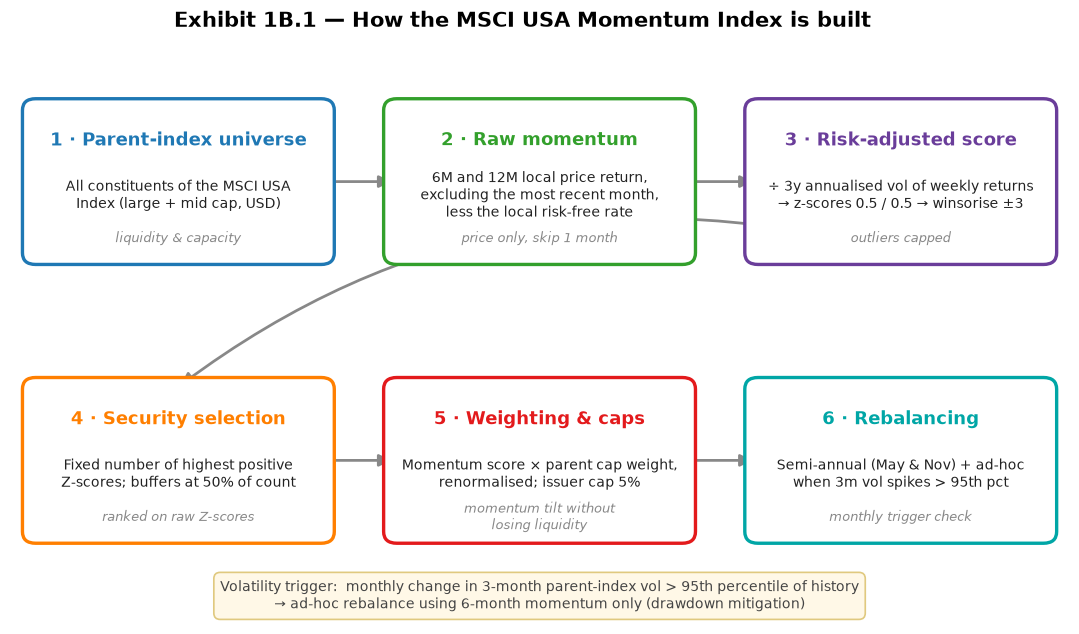

In [6]:
# Exhibit 1B.1 — schematic of the MSCI momentum construction pipeline
fig, ax = plt.subplots(figsize=(12.4, 6.4))
ax.set_xlim(0, 12); ax.set_ylim(0, 7); ax.axis("off")
ax.grid(False)
fig.suptitle("Exhibit 1B.1 — How the MSCI USA Momentum Index is built", fontsize=14,
             fontweight="bold", y=0.98)

boxes = [
    (0.25, 4.75, C["market"], "1 · Parent-index universe",
     "All constituents of the MSCI USA\nIndex (large + mid cap, USD)", "liquidity & capacity"),
    (4.35, 4.75, C["pos"], "2 · Raw momentum",
     "6M and 12M local price return,\nexcluding the most recent month,\nless the local risk-free rate",
     "price only, skip 1 month"),
    (8.45, 4.75, C["minvol"], "3 · Risk-adjusted score",
     "÷ 3y annualised vol of weekly returns\n→ z-scores 0.5 / 0.5 → winsorise ±3",
     "outliers capped"),
    (0.25, 1.15, C["ew"], "4 · Security selection",
     "Fixed number of highest positive\nZ-scores; buffers at 50% of count",
     "ranked on raw Z-scores"),
    (4.35, 1.15, C["momentum"], "5 · Weighting & caps",
     "Momentum score × parent cap weight,\nrenormalised; issuer cap 5%",
     "momentum tilt without\nlosing liquidity"),
    (8.45, 1.15, "#00A6A6", "6 · Rebalancing",
     "Semi-annual (May & Nov) + ad-hoc\nwhen 3m vol spikes > 95th pct",
     "monthly trigger check"),
]
w, h = 3.3, 1.9
for x, y, c, title, body, note in boxes:
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.12,rounding_size=0.15",
                                lw=2.2, edgecolor=c, facecolor="white", zorder=2))
    ax.text(x + w / 2, y + h - 0.42, title, ha="center", va="center",
            fontsize=11.5, fontweight="bold", color=c, zorder=3)
    ax.text(x + w / 2, y + h / 2 - 0.18, body, ha="center", va="center",
            fontsize=9.3, color="#222222", zorder=3)
    ax.text(x + w / 2, y + 0.22, note, ha="center", va="center",
            fontsize=8.2, color="#888888", style="italic", zorder=3)


def _arrow(p1, p2, rad=0.0):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle="-|>", mutation_scale=16, lw=1.8,
                                 color="#888888", connectionstyle=f"arc3,rad={rad}", zorder=1))


_arrow((3.55, 5.7), (4.35, 5.7)); _arrow((7.65, 5.7), (8.45, 5.7))
_arrow((10.1, 4.75), (1.9, 3.05), rad=0.25)
_arrow((3.55, 2.1), (4.35, 2.1)); _arrow((7.65, 2.1), (8.45, 2.1))
ax.text(6.0, 0.35,
        "Volatility trigger:  monthly change in 3-month parent-index vol > 95th percentile of history\n"
        "→ ad-hoc rebalance using 6-month momentum only (drawdown mitigation)",
        ha="center", va="center", fontsize=9.2, color="#444444",
        bbox=dict(boxstyle="round,pad=0.45", facecolor="#FFF8E7", edgecolor="#E0C97F", lw=1.1))
save_exhibit(fig, "1b_msci_pipeline")

**Our summary of the methodology (paraphrased).**

* **Investable universe.** Every security in the relevant **MSCI parent index** — for the MSCI USA Momentum Index, the MSCI USA Standard (large + mid cap) universe. Using the parent universe guarantees the opportunity set already has liquidity and investment capacity; there is no separate liquidity screen.
* **What "momentum" is measured on.** Recent **local price performance over 12 and 6 months, always skipping the most recent month** (price at *T−1* vs *T−13* and *T−7*, where *T* is the rebalancing date), **less the local risk-free rate**. The one-month skip is the classic Jegadeesh–Titman *12–1* construction that avoids short-term reversal contamination. If 12-month momentum is unavailable only 6-month momentum is used; if 6-month momentum is missing, the stock cannot be included. Momentum is based on price, not total return or fundamentals.
* **Standardisation and outliers.** Each horizon's momentum is first **risk-adjusted** by dividing by the annualised standard deviation of weekly local returns over the past three years. The risk-adjusted values are converted to cross-sectional **z-scores**, blended **50/50** into one momentum *Z*-score, then **winsorised at ±3** so a handful of extreme scores cannot dominate. The score is then mapped to a positive multiplier, $S = 1 + Z$ for $Z>0$ and $S = 1/(1-Z)$ for $Z<0$, so winners score above 1 and losers below 1.
* **Selection of "high momentum" stocks.** A **fixed number of securities** is selected — predetermined per index at construction with an algorithm that balances momentum exposure against sufficient market-cap and count coverage (rounded to the nearest 10/25/50 securities) and re-evaluated at each semi-annual review. Stocks are ranked by their **unwinsorised** *Z*-score descending and the highest positive scores are kept. **Buffer rules** at 50% of the target count (e.g. ranks 251–750 around a target of 500) limit turnover from borderline names.
* **Weighting.** Weights are proportional to **momentum score × the stock's market-cap weight in the parent index**, then renormalised. So the index is **not** a pure momentum bet: it is a market-cap index **tilted towards winners**. *Two benefits:* (i) it keeps the index highly investable and liquid — it avoids piling into small, illiquid winners — and (ii) it keeps the index's market beta and tracking error close to the parent, making it usable as a core equity allocation rather than a niche satellite. *One cost:* the momentum signal is diluted — a mega-cap with only modest momentum still receives a large weight, lowering the index's factor purity, and the index inherits parent concentration risk.
* **Rebalance frequency.** Scheduled **semi-annual** reviews, effective after the close of the last business day of **May and November**, aligned with the parent index's Semi-Annual Index Reviews. Pro-forma changes are announced around nine business days before the effective date.
* **Trigger-based ad-hoc reconstitutions.** The trigger is checked **monthly**: if the change in the parent index's trailing 3-month annualised volatility versus the prior month exceeds the **95th percentile** of historical monthly volatility changes, an ad-hoc rebalance is run, using **only 6-month momentum**. This is investor-friendly because it is designed to **mitigate drawdowns during volatility spikes and momentum crashes**, refreshing the portfolio toward the newest price signal when the old one is most likely stale; the trade-off is extra turnover and the risk of reacting to noise.
* **Weight cap.** For broad regional/country indexes such as **MSCI USA Momentum, an issuer is capped at 5%** of the index (narrow single-country indexes use the maximum parent-index weight instead). Individual mega-caps such as NVIDIA therefore cannot overwhelm the index.

**Contrast with Fama-French HML.** FF sort US stocks into **2×3 independent size and book-to-market groups** (each June, using December book value and June market cap from the prior year), value-weight each of the six portfolios, and define HML as the average of the two *high* B/M portfolios minus the average of the two *low* B/M portfolios. HML is therefore a pure **accounting value spread on the broad, all-cap CRSP universe with cap weighting inside portfolios**, versus MSCI's **multi-indicator, large/mid-cap, score-tilted** value index — which is exactly why the two value series in 1D are correlated but far from identical.

## 1C · Benefits of factor diversification

> **Question.** Build a multi-factor index as the simple average of the value, minimum-volatility, equal-weighted and momentum indexes. For the six MSCI indexes plus the risk-free asset (FF RF), compute the annualised average return for 1995–July 2023 and each Sharpe ratio. Compare average return and risk-adjusted return, and discuss the multi-factor index.

Definitions used below:

$$ r^{\text{ann}}_{\text{geo}} = \left[\prod_t (1 + r_t)\right]^{12/N} - 1, \qquad
\hat\sigma_{\text{ann}} = \sqrt{12}\,\mathrm{std}(r_t), \qquad
SR = \frac{12\,(\bar r - \overline{RF})}{\hat\sigma_{\text{ann}}}. $$

Returns are in percent, transformed to decimals before compounding. The Sharpe ratio uses arithmetic means, the standard convention.

In [7]:
MSCI_LABELS = {
    "USA Standard (Large+Mid Cap)": ("USA market", C["market"]),
    "USA VALUE Standard (Large+Mid Cap)": ("Value", C["value"]),
    "USA MINIMUM VOLATILITY (USD) Standard (Large+Mid Cap)": ("Min Vol", C["minvol"]),
    "USA EQUAL WEIGHTED Standard (Large+Mid Cap)": ("Equal Weight", C["ew"]),
    "USA MOMENTUM Standard (Large+Mid Cap)": ("Momentum", C["momentum"]),
}

idx = msci.index.intersection(ff3.index)
msci_px = msci.loc[idx] / 100.0                                  # decimals
rf = ff3.loc[idx, "RF"] / 100.0                                  # decimals
short_names = {long: label for long, (label, _) in MSCI_LABELS.items()}
multi = msci_px[list(MSCI_LABELS)].mean(axis=1)
index_returns = msci_px[list(MSCI_LABELS)].rename(columns=short_names)
index_returns["Multi-factor"] = multi
index_returns["Risk-free (RF)"] = rf

rows = []
for name, x in index_returns.items():
    n = len(x)
    geo = (1 + x).prod() ** (12 / n) - 1
    vol = x.std(ddof=1) * np.sqrt(12)
    sharpe = (x.mean() * 12 - rf.mean() * 12) / vol
    rows.append({"Index": name, "Ann. return (geo) %": geo * 100,
                 "Ann. vol %": vol * 100, "Sharpe ratio": sharpe})
performance = pd.DataFrame(rows).set_index("Index")
colour_map = {label: c for label, c in MSCI_LABELS.values()}
colour_map["Multi-factor"] = C["multi"]
colour_map["Risk-free (RF)"] = C["neutral"]

(
    performance.style
    .format({"Ann. return (geo) %": "{:+.2f}", "Ann. vol %": "{:.2f}", "Sharpe ratio": "{:.2f}"})
    .set_caption("Table 1C.1 — MSCI USA indexes and the risk-free asset, January 1995 to July 2023 (gross USD).")
    .background_gradient(subset=["Sharpe ratio"], cmap="RdYlGn")
)

,Ann. return (geo) %,Ann. vol %,Sharpe ratio
Index,,,
USA market,+10.49,15.44,0.59
Value,+9.05,15.27,0.50
Min Vol,+10.13,12.09,0.68
Equal Weight,+10.82,17.13,0.56
Momentum,+12.72,16.34,0.69
Multi-factor,+10.77,14.55,0.63
Risk-free (RF),+2.18,0.61,0.00


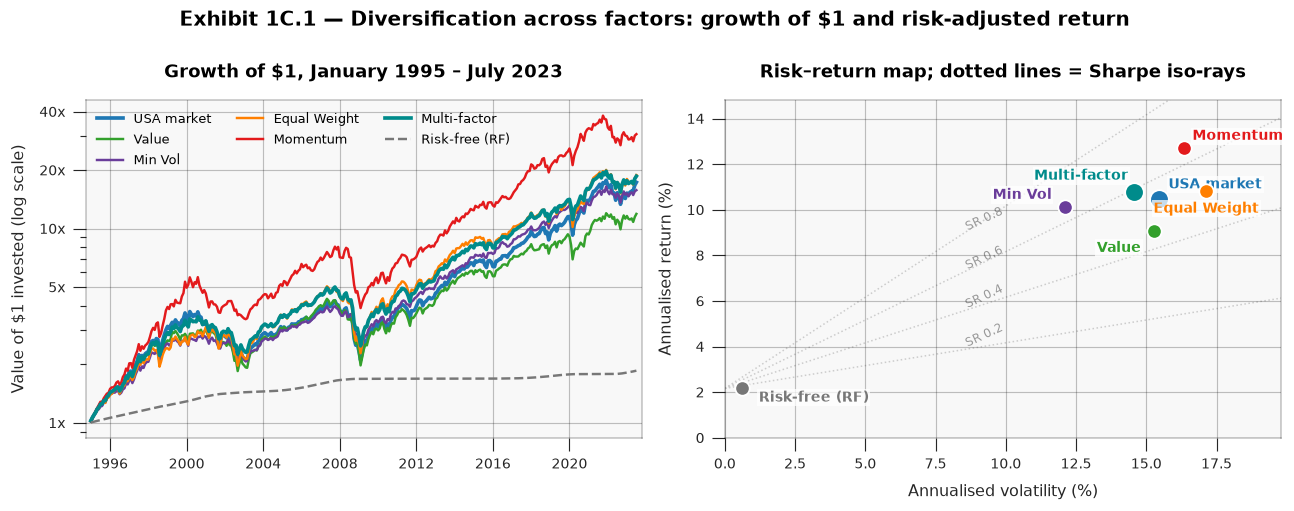

In [8]:
# Exhibit 1C.1 — growth of $1 (log scale) + risk-return map with Sharpe iso-lines
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.0, 4.6))

for name, x in index_returns.items():
    ls = "--" if name == "Risk-free (RF)" else "-"
    lw = 2.4 if name in ("USA market", "Multi-factor") else 1.6
    ax1.plot(x.index.to_timestamp(), (1 + x).cumprod(), color=colour_map[name], lw=lw, ls=ls, label=name)
ax1.set_yscale("log")
ax1.set_yticks([1, 5, 10, 20, 40])
ax1.set_yticklabels(["1x", "5x", "10x", "20x", "40x"])
ax1.set_ylabel("Value of $1 invested (log scale)")
ax1.set_title("Growth of $1, January 1995 – July 2023", fontsize=11.5)
ax1.legend(ncol=3, fontsize=8.5, loc="upper left")
ax1.margins(x=0.01)

rf_ann = rf.mean() * 12 * 100
for sr in [0.2, 0.4, 0.6, 0.8]:
    xline = np.array([0, 19.8])
    ax2.plot(xline, rf_ann + sr * xline, color="#CCCCCC", lw=1.0, ls=":", zorder=1)
    ax2.text(8.5, rf_ann + sr * 8.5, f"SR {sr:.1f}", color="#999999", fontsize=8,
             rotation=25, va="bottom", ha="left", zorder=1)

point_offsets = {"USA market": (0.35, 0.45, "left"), "Value": (-0.45, -0.9, "right"),
                 "Min Vol": (-0.45, 0.35, "right"), "Equal Weight": (0.0, -0.95, "center"),
                 "Momentum": (0.3, 0.35, "left"), "Multi-factor": (-0.2, 0.55, "right"),
                 "Risk-free (RF)": (0.6, -0.6, "left")}
for name in performance.index:
    r_ann = performance.loc[name, "Ann. return (geo) %"]
    v_ann = performance.loc[name, "Ann. vol %"]
    label = name
    c = colour_map[label]
    ms = 150 if name in ("USA market", "Multi-factor") else 90
    ax2.scatter(v_ann, r_ann, s=ms, color=c, zorder=3, edgecolor="white", lw=1.2)
    dx, dy, ha = point_offsets.get(name, (0.3, 0.3, "left"))
    ax2.annotate(label, (v_ann, r_ann), xytext=(v_ann + dx, r_ann + dy),
                 fontsize=9, color=c, fontweight="bold", ha=ha,
                 bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.0))
ax2.set_xlim(0, 19.8); ax2.set_ylim(0, 14.8)
ax2.set_xlabel("Annualised volatility (%)")
ax2.set_ylabel("Annualised return (%)")
ax2.set_title("Risk–return map; dotted lines = Sharpe iso-rays", fontsize=11.5)

fig.suptitle("Exhibit 1C.1 — Diversification across factors: growth of $1 and risk-adjusted return",
             fontsize=13, fontweight="bold", y=1.0)
fig.tight_layout()
save_exhibit(fig, "1c_growth_and_risk_return")

**Comment.** Momentum delivered the highest return, **+12.7%/yr**, and the joint-highest Sharpe ratio (**0.69**), narrowly ahead of Min Vol (0.68). Value was the **worst** index on both counts (+9.1%/yr, Sharpe 0.50), reflecting the well-documented post-2008 value winter. Equal Weight earned a similar return to the multi-factor index (+10.8%) but with by far the **highest volatility (17.1%)** and the worst drawdown profile — equally weighting a market dominated by mega-caps is a size/anti-cap tilt, not a low-risk strategy.

The **multi-factor index** is the sensible core allocation here: +10.8%/yr (slightly above the market's +10.5%) at **lower volatility** (14.4% vs 15.4%) and a **higher Sharpe ratio** (0.64 vs 0.59). Nothing in it is spectacular on its own, but averaging four imperfectly correlated tilts (Exhibit 1C.1, right) raises risk-adjusted return relative to the market — exactly the factor-diversification argument from class. Note the multi-factor average does not outperform Momentum alone; combining factors trades maximum return for much better consistency.

## 1D · Sensitivity of factor returns to factor portfolio construction

> **Question.** For each month in 1995–July 2023, compute the spread of each MSCI smart-beta index over the MSCI USA market index, then correlate each spread with each FF monthly spread: HML, SMB, winners-minus-losers momentum and low-minus-high beta — all value-weighted. Present a 4×4 correlation table and comment.

The MSCI spreads are $(r_{\text{smart-beta}} - r_{\text{USA market}})$ in percent per month. The FF spreads are HML and SMB from the FF3 file, the value-weighted **Hi−Lo prior-return** decile spread, and the value-weighted **Lo−Hi beta** decile spread. Overlap: January 1995 – July 2023 (the beta portfolios begin in July 1963).

In [9]:
spreads = pd.DataFrame({
    "Value − Mkt": msci_px["USA VALUE Standard (Large+Mid Cap)"] - msci_px["USA Standard (Large+Mid Cap)"],
    "MinVol − Mkt": msci_px["USA MINIMUM VOLATILITY (USD) Standard (Large+Mid Cap)"] - msci_px["USA Standard (Large+Mid Cap)"],
    "EqualWgt − Mkt": msci_px["USA EQUAL WEIGHTED Standard (Large+Mid Cap)"] - msci_px["USA Standard (Large+Mid Cap)"],
    "Momentum − Mkt": msci_px["USA MOMENTUM Standard (Large+Mid Cap)"] - msci_px["USA Standard (Large+Mid Cap)"],
}, index=idx) * 100

ff_spreads = pd.DataFrame({
    "HML": ff3.loc[idx, "HML"],
    "SMB": ff3.loc[idx, "SMB"],
    "UMD": umd.loc[idx],
    "BAB": bab.loc[idx],
})

corr = pd.DataFrame({b: {a: spreads[a].corr(ff_spreads[b]) for a in spreads} for b in ff_spreads})
(
    corr.style
    .format("{:.2f}")
    .set_caption("Table 1D.1 — Correlation of MSCI smart-beta spreads (rows) with FF value-weighted spreads (columns), 1995-01 to 2023-07.")
    .background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)
)

,HML,SMB,UMD,BAB
Value − Mkt,0.73,-0.18,-0.24,0.41
MinVol − Mkt,0.23,-0.31,0.30,0.81
EqualWgt − Mkt,0.43,0.32,-0.45,-0.20
Momentum − Mkt,-0.22,0.08,0.64,0.14


/var/folders/r9/dyfdvd_j5_15pz3fkwg9rjr40000gn/T/ipykernel_71802/1617840898.py:33: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


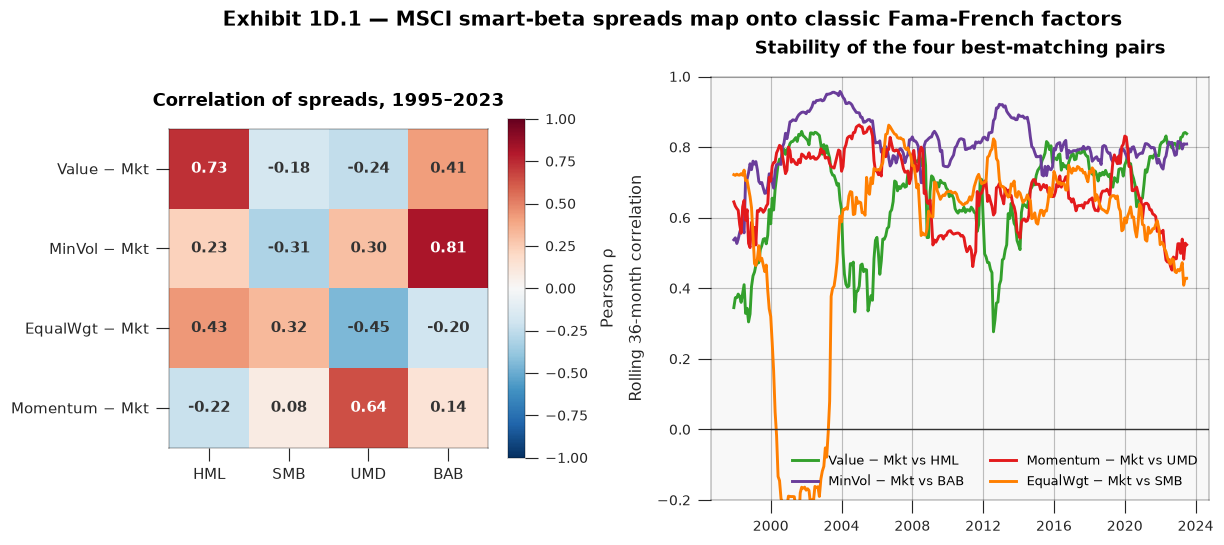

In [10]:
# Exhibit 1D.1 — annotated correlation heatmap + rolling 36-month correlations
fig = plt.figure(figsize=(12.2, 5.0))
gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.25], wspace=0.32)

ax = fig.add_subplot(gs[0])
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, fontsize=9.5)
ax.set_yticks(range(len(corr.index)), corr.index, fontsize=9.5)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=10,
                color="white" if abs(v) > 0.55 else "#333333", fontweight="bold")
ax.set_title("Correlation of spreads, 1995–2023", fontsize=11.5)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson ρ")

ax2 = fig.add_subplot(gs[1])
pairs = [("Value − Mkt", "HML", C["value"]), ("MinVol − Mkt", "BAB", C["minvol"]),
         ("Momentum − Mkt", "UMD", C["momentum"]), ("EqualWgt − Mkt", "SMB", C["ew"])]
for spread, factor, colour in pairs:
    roll_corr = spreads[spread].rolling(36).corr(ff_spreads[factor])
    ax2.plot(roll_corr.index.to_timestamp(), roll_corr, color=colour, lw=1.9,
             label=f"{spread} vs {factor}")
ax2.axhline(0, color="#333333", lw=0.9)
ax2.set_ylim(-0.2, 1.0)
ax2.set_ylabel("Rolling 36-month correlation")
ax2.set_title("Stability of the four best-matching pairs", fontsize=11.5)
ax2.legend(fontsize=8.5, loc="lower right", ncol=2)

fig.suptitle("Exhibit 1D.1 — MSCI smart-beta spreads map onto classic Fama-French factors",
             fontsize=13, fontweight="bold", y=1.0)
fig.tight_layout()
save_exhibit(fig, "1d_correlation_analysis")

**Comment.** All four MSCI tilts line up with the intended classic factor, but none is a pure clone:

* **Value ↔ HML ρ = 0.73** — the strongest match, and the one the assignment asks us to explain. Both spreads buy cheap stocks, but MSCI uses multiple valuation indicators (B/P plus earnings, dividends, cash-flow and sales multiples), only large/mid caps and momentum-tilted cap weights, while FF HML is a pure book-to-market spread on the all-cap universe. Same style, different recipe — so ρ is high but not 1.
* **Min Vol ↔ BAB ρ = 0.81** — almost by construction: both are long low-beta/low-volatility stocks against high-beta names. This is the highest correlation in the table and confirms that "minimum volatility" is largely a low-beta strategy.
* **Momentum ↔ UMD ρ = 0.64** — clearly momentum, but MSCI's 12/6-month score, risk adjustment, cap-tilted weights and semi-annual rebalancing produce a diluted version of the academic 12–1 spread.
* **Equal Weight ↔ SMB ρ = 0.32** and **Equal Weight ↔ UMD ρ = −0.45** — Equal Weight is the least "single-factor" tilt: against a mega-cap-dominated benchmark it behaves like a broad size/anti-concentration bet and, because it holds recent winners *and* losers, it leans against price momentum.

The rolling correlations (right panel) are reassuring: Value–HML and MinVol–BAB stay strongly positive through the sample. The momentum pair fell below zero during the 2000–2002 technology bust and again briefly in 2021, a reminder that index construction can make the MSCI momentum spread temporarily diverge from the academic factor.

## 1E · Regime-sensitivity of factor premia

> **Question.** Using trailing 12-month market volatility from FF excess market returns (starting Dec 1995) and the value-weighted FF momentum spread from 1A (Dec 1995 – Jul 2023), analyse statistically whether momentum profitability depends on the level of recent market volatility.

We use three complementary views: (i) a conditional-mean regression with Newey–West errors, (ii) a tercile comparison of momentum returns across low/mid/high trailing-volatility regimes, and (iii) **quantile regressions** — because what may matter for a momentum investor is not only the average outcome but how volatility reshapes the *distribution*, especially the left tail.

$$\hat\sigma_t^{(12)} = \sqrt{12}\;\mathrm{std}(Mkt\text{-}RF_{t-11..t}), \qquad
Q_\tau(MOM_t \mid \sigma_t) = \alpha_\tau + \beta_\tau \sigma_t.$$

In [11]:
vol = (ff3["Mkt-RF"].rolling(12).std() * np.sqrt(12)).loc["1995-12":"2023-07"]  # %/yr
mom_regime = umd.loc[vol.index]
regime = pd.qcut(vol, 3, labels=["Low vol", "Mid vol", "High vol"])

tercile_rows = []
for bucket in ["Low vol", "Mid vol", "High vol"]:
    x = mom_regime[regime == bucket]
    t, p = stats.ttest_1samp(x, 0.0)
    tercile_rows.append({
        "Trailing vol regime": bucket, "Months": len(x),
        "Mean ann. vol %": vol[regime == bucket].mean(),
        "Mean mom %/mo": x.mean(), "Mean mom %/yr": x.mean() * 12,
        "t-stat": t, "p-value": p, "Hit rate": (x > 0).mean(),
    })
terciles = pd.DataFrame(tercile_rows).set_index("Trailing vol regime")

X = sm.add_constant(vol)
ols = sm.OLS(mom_regime, X).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
taus = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
qr_fits = {tau: sm.QuantReg(mom_regime, X).fit(q=tau, max_iter=10000) for tau in taus}
slopes = pd.Series({tau: qr_fits[tau].params.iloc[1] for tau in taus})
slope_ts = pd.Series({tau: qr_fits[tau].tvalues.iloc[1] for tau in taus})

print(f"OLS (HAC 12 lags): const = {ols.params.iloc[0]:+.2f}  slope = {ols.params.iloc[1]:+.3f} "
      f"(t = {ols.tvalues.iloc[1]:+.2f}),  R2 = {ols.rsquared:.3f}")
print("\nWorst 5 momentum months:")
print(pd.DataFrame({"MOM %": mom_regime.nsmallest(5), "Trailing vol %": vol.loc[mom_regime.nsmallest(5).index]}).round(1))

(
    terciles.style
    .format({"Months": "{:.0f}", "Mean ann. vol %": "{:.1f}", "Mean mom %/mo": "{:+.2f}",
             "Mean mom %/yr": "{:+.1f}", "t-stat": "{:+.2f}", "p-value": "{:.3f}", "Hit rate": "{:.0%}"})
    .set_caption("Table 1E.1 — Momentum profitability by trailing 12-month market-volatility tercile, Dec 1995 – Jul 2023.")
    .background_gradient(subset=["Mean mom %/yr", "t-stat"], cmap="RdYlGn")
)

OLS (HAC 12 lags): const = +4.53  slope = -0.267 (t = -2.30),  R2 = 0.032

Worst 5 momentum months:
         MOM %  Trailing vol %
date                          
2009-04  -45.2            28.8
2001-01  -42.1            18.9
2009-03  -39.6            26.4
2020-04  -28.8            24.8
2020-11  -26.7            27.6


,Months,Mean ann. vol %,Mean mom %/mo,Mean mom %/yr,t-stat,p-value,Hit rate
Trailing vol regime,,,,,,,
Low vol,111,8.2,+1.04,+12.5,+2.20,0.030,60%
Mid vol,110,14.2,+1.86,+22.3,+2.57,0.012,63%
High vol,111,21.5,-1.03,-12.3,-0.88,0.380,56%


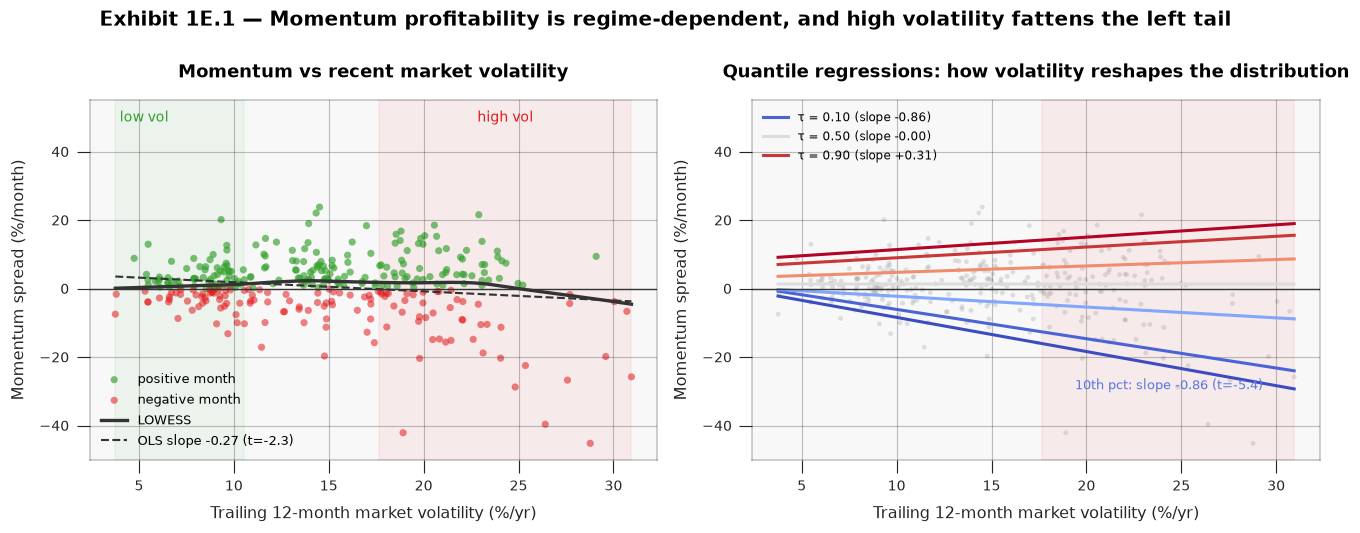

In [12]:
# Exhibit 1E.1 — momentum vs volatility: scatter/LOWESS and quantile-regression fan
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.8))

q33, q67 = vol.quantile([1/3, 2/3])
ax1.axvspan(vol.min(), q33, color=C["pos"], alpha=0.06, zorder=0)
ax1.axvspan(q67, vol.max(), color=C["neg"], alpha=0.06, zorder=0)
ax1.text(q33 / 2, 52, "low vol", color=C["pos"], fontsize=9, ha="center", va="top")
ax1.text((q67 + vol.max()) / 2, 52, "high vol", color=C["neg"], fontsize=9, ha="center", va="top")
neg = mom_regime < 0
ax1.scatter(vol[~neg], mom_regime[~neg], s=22, color=C["pos"], alpha=0.65, edgecolor="none", label="positive month")
ax1.scatter(vol[neg], mom_regime[neg], s=22, color=C["neg"], alpha=0.55, edgecolor="none", label="negative month")
line = lowess(mom_regime, vol, frac=0.45, return_sorted=True)
ax1.plot(line[:, 0], line[:, 1], color="#333333", lw=2.2, label="LOWESS")
vol_sorted = vol.sort_values()
ax1.plot(vol_sorted, ols.params.iloc[0] + ols.params.iloc[1] * vol_sorted,
         color="#333333", lw=1.4, ls="--", label=f"OLS slope {ols.params.iloc[1]:+.2f} (t={ols.tvalues.iloc[1]:.1f})")
ax1.axhline(0, color="#333333", lw=0.9)
ax1.set_xlabel("Trailing 12-month market volatility (%/yr)")
ax1.set_ylabel("Momentum spread (%/month)")
ax1.set_title("Momentum vs recent market volatility", fontsize=11.5)
ax1.set_ylim(-50, 55)
ax1.legend(fontsize=8.5, loc="lower left")

cmap = plt.get_cmap("coolwarm")
xgrid = np.linspace(vol.min(), vol.max(), 60)
for tau in taus:
    colour = cmap((tau - 0.05) / 0.9)
    ygrid = qr_fits[tau].params.iloc[0] + qr_fits[tau].params.iloc[1] * xgrid
    ax2.plot(xgrid, ygrid, color=colour, lw=2.0,
             label=f"τ = {tau:.2f} (slope {slopes[tau]:+.2f})" if tau in (0.10, 0.50, 0.90) else None)
ax2.scatter(vol, mom_regime, s=10, color="#AAAAAA", alpha=0.35, edgecolor="none", zorder=0)
ax2.axhline(0, color="#333333", lw=0.9)
ax2.axvspan(q67, vol.max(), color=C["neg"], alpha=0.06, zorder=0)
ax2.set_xlabel("Trailing 12-month market volatility (%/yr)")
ax2.set_ylabel("Momentum spread (%/month)")
ax2.set_title("Quantile regressions: how volatility reshapes the distribution", fontsize=11.5)
ax2.set_ylim(-50, 55)
ax2.legend(fontsize=8)
ax2.annotate(f"10th pct: slope {slopes[0.10]:+.2f} (t={slope_ts[0.10]:.1f})",
             xy=(vol.max() - 1, qr_fits[0.10].params.iloc[0] + qr_fits[0.10].params.iloc[1] * (vol.max() - 1)),
             xytext=(-8, -14), textcoords="offset points", fontsize=8.5, color=cmap(0.10), ha="right")

fig.suptitle("Exhibit 1E.1 — Momentum profitability is regime-dependent, and high volatility fattens the left tail",
             fontsize=13, fontweight="bold", y=1.0)
fig.tight_layout()
save_exhibit(fig, "1e_momentum_regime")

**Comment.** Momentum profitability is clearly state-dependent:

* **Conditional means.** In the lowest trailing-volatility tercile the spread averaged **+12.5%/yr** (*t* = 2.2) and in the middle tercile **+22.3%/yr** (*t* = 2.6), but in the **highest** volatility tercile it averaged **−12.3%/yr** and is statistically indistinguishable from zero (*t* = −0.9). The unconditional +13.6%/yr average is therefore not something an investor could have earned in every environment.
* **Regression.** The OLS slope on trailing volatility is **−0.27** (*t* = −2.3 with 12-lag Newey–West errors): each additional percentage point of recent market volatility is associated with a lower average momentum return of about 0.27%/month. The *R*² of 0.03 is deliberately sobering — volatility explains only a small share of month-to-month variation, so this is a risk-management signal, not a market-timing rule.
* **Distribution, not just the mean.** The quantile regressions are the most informative result. The 10th-percentile slope is **−0.85** (*t* = −5.4): high volatility strongly *deepens the left tail* of momentum outcomes. The median slope is ≈ 0, and the 90th-percentile slope is mildly positive (+0.31), so higher volatility widens both tails but pushes the mean down — the signature of **momentum crashes**.
* **The crash months tell the story.** The five worst momentum months in the sample — April 2009 (−45%), January 2001 (−42%), March 2009 (−40%), April 2020 (−29%) and November 2020 (−27%) — are all rebounds from market crises, and **67% of the worst decile of momentum months occurred in the highest-volatility tercile**.

**Practical implication.** Because momentum's expected return and crash risk both worsen when recent market volatility is high, a momentum allocation should be sized conditionally (e.g. scaled down with trailing volatility or combined with a defensive factor such as Min Vol, whose spread was strongly tied to low-beta/BAB and which held up comparatively well in stress). That is also precisely the rationale behind MSCI's volatility-triggered ad-hoc rebalancing in 1B.

## Conclusion

1. **The FF3 story has changed since publication.** The market premium survived; size and value premia lost statistical significance in the post-1992 sample, though value's rolling premium has not been permanently zero.
2. **Momentum is strong on average and weak when it matters.** Its unconditional +13.6%/yr coexists with a −12.3%/yr conditional outcome in high-volatility regimes and a heavy left tail driven by post-crisis rebounds.
3. **Factor diversification works for an investor, not just in theory.** A simple average of four MSCI smart-beta indexes beat the market's Sharpe ratio (0.64 vs 0.59) with lower volatility, even though none of its components is a pure academic factor.
4. **Index construction is a series of deliberate trade-offs.** MSCI's momentum methodology (price-only 12/6-month score, risk-adjusted and winsorised, score × parent-cap weights, 5% issuer cap, semi-annual plus volatility-triggered rebalancing) makes the factor investable and close to the market, at the cost of dilution and off-cycle rebalances — visible in the ~0.6–0.8 correlations with the classic FF spreads.

*Limitations to keep in mind for the write-up:* correlations and premia are unconditional or simply conditioned summaries, FF data are backfilled/updated, and all returns are gross of transaction costs and taxes — turnover-heavy strategies such as momentum and equal-weighting would look worse net.

---

### References

1. Fama, E. & French, K. (1992). *The Cross-Section of Expected Stock Returns.* Journal of Finance 47(2).
2. Fama, E. & French, K. (2015). *A Five-Factor Asset Pricing Model.* Journal of Financial Economics 116(1).
3. Jegadeesh, N. & Titman, S. (1993). *Returns to Buying Winners and Selling Losers.* Journal of Finance 48(1).
4. Frazzini, A. & Pedersen, L. (2014). *Betting Against Beta.* Journal of Financial Economics 111(1).
5. MSCI (2013). *MSCI Momentum Indexes Methodology.* msci.com/eqb/methodology/meth_docs/MSCI_Momentum_Indices_Methodology.pdf
6. Kenneth R. French Data Library (2023 vintage). U.S. Research Returns Data. mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html
7. MSCI end-of-day index data (gross USD total returns), retrieved from the class data pack.